# Marathon Analytics
Training block comparison, trajectory analysis, taper detection, and volume forecast across all marathon builds.

In [1]:
from sqlalchemy import create_engine
import pandas as pd
import os
from dotenv import load_dotenv

load_dotenv()

host = os.getenv("SUPABASE_HOST")
user = os.getenv("SUPABASE_USER")
password = os.getenv("SUPABASE_PASSWORD")

engine = create_engine(f"postgresql+psycopg2://{user}:{password}@{host}:6543/postgres")

query = """
    SELECT
        a.activity_name, a.start_date, a.activity_type,
        a.distance, a.duration, a.elevation,
        a.max_speed, a.avg_speed, a.avg_heartrate,
        a.suffer_score, a.avg_watts, a.kilojoules,
        a.start_lat, a.start_lng, a.end_lat, a.end_lng
    FROM activities a
    JOIN athletes ath ON a.athlete_id = ath.id
    ORDER BY a.start_date DESC
"""

df = pd.read_sql(query, engine)
df["start_date"] = pd.to_datetime(df["start_date"])

splits_query = """
    SELECT
        s.id AS split_id,
        s.activity_id,
        s.split_number,
        s.distance_km,
        s.elapsed_time_s,
        s.moving_time_s,
        s.elevation_diff_m,
        s.avg_speed_kmh,
        s.avg_heartrate,
        s.pace_zone,
        a.activity_name,
        a.start_date,
        a.activity_type
    FROM splits s
    JOIN activities a ON s.activity_id = a.id
    ORDER BY a.start_date DESC, s.split_number ASC
"""

df_splits = pd.read_sql(splits_query, engine)
df_splits["start_date"] = pd.to_datetime(df_splits["start_date"])
import numpy as np
runs_ml = df[df["activity_type"] == "Run"].dropna(subset=["distance"]).copy()


## 1. Side-by-side comparison of individual run distances across three marathon training blocks.
Each dot is one run; the fill shows the volume envelope over time. 7-day rolling avg: mean distance of the last 7 runs (not calendar days), smoothing out the natural spike-and-dip between hard long runs and short recovery runs to reveal whether the training load is building, holding, or tapering.

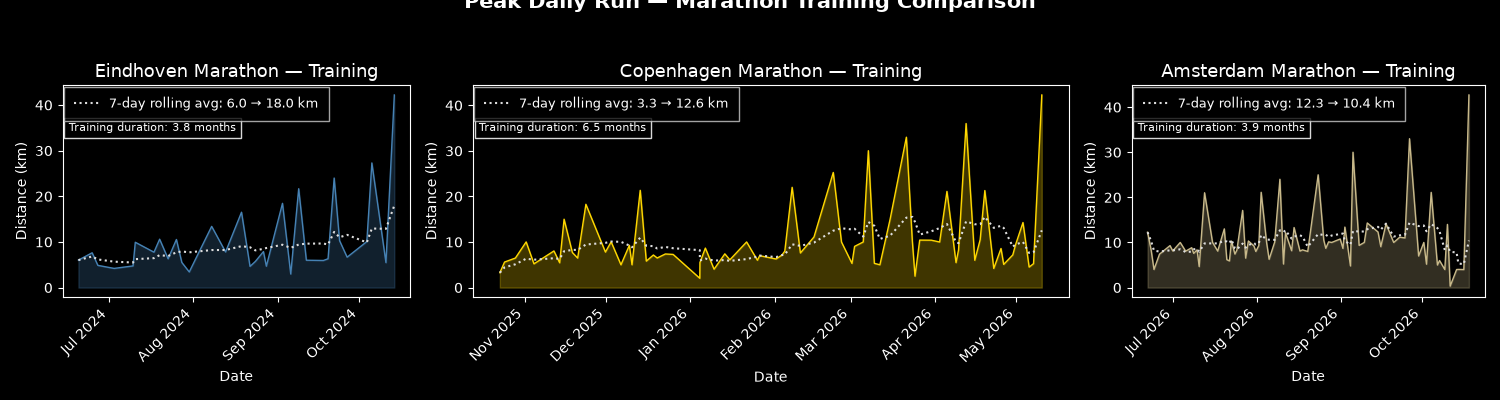

In [2]:
%matplotlib widget
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import mplcursors
import pandas as pd
from dotenv import load_dotenv
load_dotenv()

FIGURES_DIR = os.path.join(os.getenv("FIGURES_DIR"), "MarathonAnalytics")
os.makedirs(FIGURES_DIR, exist_ok=True)

CREAM = "#C8B98A"

runs = (df[df["activity_type"] == "Run"]
        .dropna(subset=["distance"])
        .sort_values("start_date"))

def max_per_day(data):
    return data.loc[data.groupby(data["start_date"].dt.date)["distance"].idxmax()]

marathon1 = max_per_day(runs[(runs["start_date"] >= "2024-06-01") & (runs["start_date"] < "2024-10-14")])
marathon2 = runs[(runs["start_date"] >= "2025-10-20") & (runs["start_date"] < "2026-05-11")]
marathon3 = max_per_day(runs[(runs["start_date"] >= "2026-06-15") & (runs["start_date"] < "2026-10-19")])

duration1 = (marathon1["start_date"].iloc[-1] - marathon1["start_date"].iloc[0]).days
duration2 = (marathon2["start_date"].iloc[-1] - marathon2["start_date"].iloc[0]).days
duration3 = (marathon3["start_date"].iloc[-1] - marathon3["start_date"].iloc[0]).days

fig, (ax1, ax2, ax3) = plt.subplots(
    1, 3, figsize=(15, 4),
    gridspec_kw={"width_ratios": [duration1, duration2, duration3]}
)

cursors = []
legends = []
axes_meta = []

for ax, data, title, color in [
    (ax1, marathon1, "Eindhoven Marathon — Training", "steelblue"),
    (ax2, marathon2, "Copenhagen Marathon — Training", "gold"),
    (ax3, marathon3, "Amsterdam Marathon — Training", CREAM),
]:
    line, = ax.plot(data["start_date"], data["distance"], linewidth=1, color=color)
    ax.fill_between(data["start_date"], 0, data["distance"], alpha=0.25, color=color)

    rolling_avg = data["distance"].rolling(7, min_periods=1).mean()
    ax.plot(data["start_date"], rolling_avg, ":", color="#DDDDDD", linewidth=1.5, zorder=5,
            label=f"7-day rolling avg: {rolling_avg.iloc[0]:.1f} → {rolling_avg.iloc[-1]:.1f} km")
    legend = ax.legend(loc="upper left", fontsize=9)
    legend.get_frame().set_boxstyle("square,pad=0.4")
    legends.append(legend)

    training_months = (data["start_date"].iloc[-1] - data["start_date"].iloc[0]).days / 30.44
    axes_meta.append((ax, training_months))

    ax.set_title(title, fontsize=13)
    ax.set_xlabel("Date")
    ax.set_ylabel("Distance (km)")
    ax.xaxis.set_major_locator(mdates.MonthLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right")

    cursor = mplcursors.cursor(line, hover=False)
    cursors.append(cursor)
    prev_sel = [None]

    @cursor.connect("add")
    def on_add(sel, d=data, p=prev_sel):
        if p[0] is not None:
            p[0].annotation.set_visible(False)
            fig.canvas.draw_idle()
        p[0] = sel
        row = d.iloc[sel.index]
        sel.annotation.set_text(
            f"{row['start_date'].strftime('%d %b %Y')}\n"
            f"Distance: {row['distance']:.1f} km\n"
            f"Suffer Score: {row.get('suffer_score', 'N/A')}"
        )

fig.suptitle("Peak Daily Run — Marathon Training Comparison", fontsize=15, fontweight="bold", y=1.02)
plt.tight_layout(rect=[0, 0, 1, 0.97])
fig.canvas.draw()

for (ax, training_months), legend in zip(axes_meta, legends):
    bbox = legend.get_window_extent()
    inv = ax.transAxes.inverted()
    x0_ax, y0_ax = inv.transform([bbox.x0, bbox.y0])
    ax.text(x0_ax, y0_ax - 0.03,
            f"Training duration: {training_months:.1f} months",
            transform=ax.transAxes,
            fontsize=8, va="top", ha="left", color="white",
            bbox=dict(boxstyle="square,pad=0.4", facecolor="black", edgecolor="white", alpha=0.85))

fig.savefig(os.path.join(FIGURES_DIR, "marathon_training_comparison.png"), dpi=150, bbox_inches="tight")
plt.show()

## 2. Marathon Training Trajectory Comparison
Weekly peak run distance and monthly total volume plotted on a shared training timeline, allowing direct comparison of how each marathon build-up progressed from month one to race day.

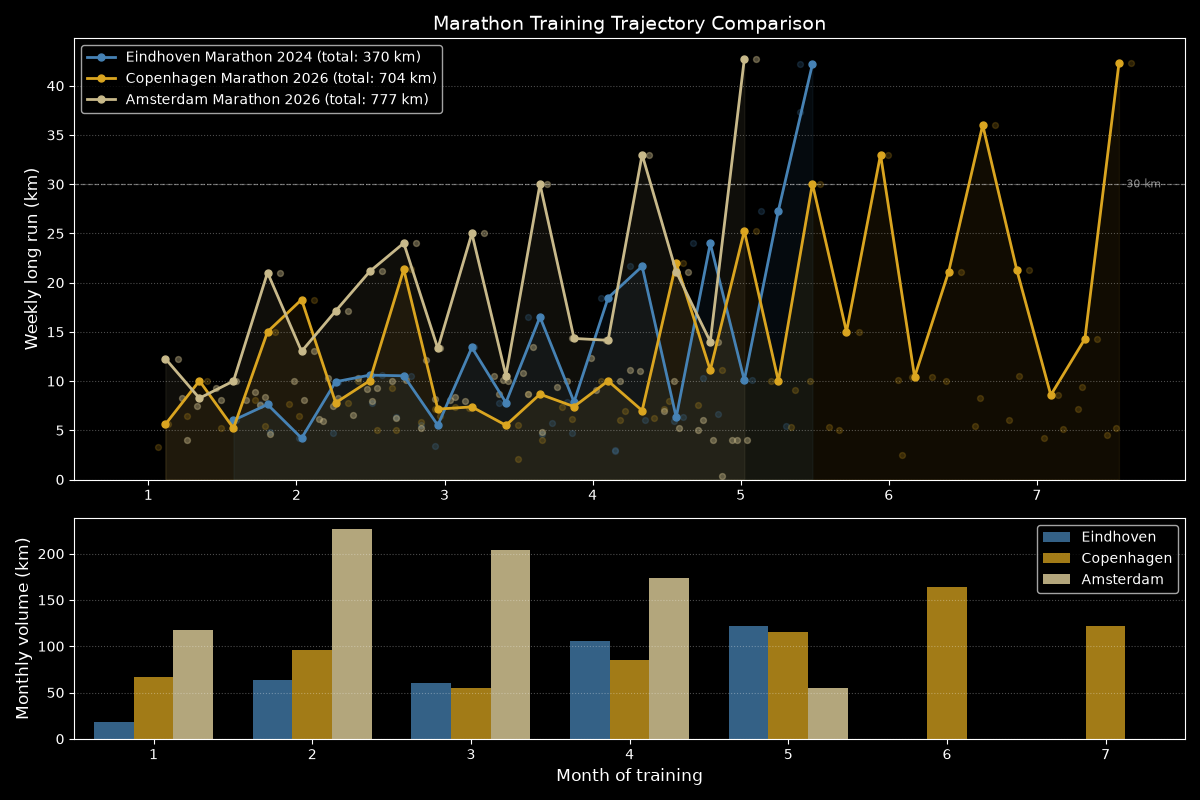

In [3]:
%matplotlib widget
import os
import matplotlib.pyplot as plt
import pandas as pd
from dotenv import load_dotenv
load_dotenv()

FIGURES_DIR = os.path.join(os.getenv("FIGURES_DIR"), "MarathonAnalytics")
os.makedirs(FIGURES_DIR, exist_ok=True)

runs = (df[df["activity_type"] == "Run"]
        .dropna(subset=["distance"])
        .sort_values("start_date"))

# Training windows
start1 = pd.Timestamp("2024-06-01")
start2 = pd.Timestamp("2025-10-20")
start3 = pd.Timestamp("2026-06-15")

m1 = runs[(runs["start_date"] >= start1) & (runs["start_date"] < "2024-10-14")].copy()
m2 = runs[(runs["start_date"] >= start2) & (runs["start_date"] < "2026-05-11")].copy()
m3 = runs[runs["start_date"] >= start3].copy()

def weekly_long_run(data, start):
    d = data.copy()
    d["week"] = (d["start_date"] - start).dt.days // 7
    wk = d.groupby("week")["distance"].max().reset_index()
    wk["month"] = (wk["week"] * 7 + 3.5) / 30.44 + 1
    return wk

def monthly_volume(data, start):
    d = data.copy()
    d["month_bin"] = (d["start_date"] - start).dt.days // 30 + 1
    return d.groupby("month_bin")["distance"].sum().reset_index().rename(
        columns={"month_bin": "month", "distance": "total_dist"})

wlr1 = weekly_long_run(m1, start1)
wlr2 = weekly_long_run(m2, start2)
wlr3 = weekly_long_run(m3, start3)
vol1  = monthly_volume(m1, start1)
vol2  = monthly_volume(m2, start2)
vol3  = monthly_volume(m3, start3)

total1 = m1["distance"].sum()
total2 = m2["distance"].sum()
total3 = m3["distance"].sum()

CREAM = "#C8B98A"

fig, (ax_top, ax_bot) = plt.subplots(
    2, 1, figsize=(12, 8),
    gridspec_kw={"height_ratios": [2, 1]}
)

# --- Top: individual runs (faded) + weekly long run line ---
ax_top.scatter(
    (m1["start_date"] - start1).dt.days / 30.44 + 1, m1["distance"],
    alpha=0.2, color="steelblue", s=18, zorder=2
)
ax_top.scatter(
    (m2["start_date"] - start2).dt.days / 30.44 + 1, m2["distance"],
    alpha=0.2, color="goldenrod", s=18, zorder=2
)
ax_top.scatter(
    (m3["start_date"] - start3).dt.days / 30.44 + 1, m3["distance"],
    alpha=0.4, color=CREAM, s=18, zorder=2
)

ax_top.plot(wlr1["month"], wlr1["distance"], color="steelblue", linewidth=2, marker="o", markersize=5,
            label=f"Eindhoven Marathon 2024 (total: {total1:.0f} km)")
ax_top.plot(wlr2["month"], wlr2["distance"], color="goldenrod",  linewidth=2, marker="o", markersize=5,
            label=f"Copenhagen Marathon 2026 (total: {total2:.0f} km)")
ax_top.plot(wlr3["month"], wlr3["distance"], color=CREAM,        linewidth=2, marker="o", markersize=5,
            label=f"Amsterdam Marathon 2026 (total: {total3:.0f} km)")
ax_top.fill_between(wlr1["month"], 0, wlr1["distance"], alpha=0.08, color="steelblue")
ax_top.fill_between(wlr2["month"], 0, wlr2["distance"], alpha=0.08, color="goldenrod")
ax_top.fill_between(wlr3["month"], 0, wlr3["distance"], alpha=0.08, color=CREAM)

# 30 km threshold reference line
ax_top.axhline(30, color="white", linewidth=0.9, linestyle="--", alpha=0.4, zorder=1)
ax_top.text(7.55, 30, "  30 km", color="white", fontsize=8, va="center", alpha=0.55, clip_on=False)

ax_top.set_ylabel("Weekly long run (km)", fontsize=12)
ax_top.set_title("Marathon Training Trajectory Comparison", fontsize=14)
ax_top.legend(loc="upper left", fontsize=10)
ax_top.set_xticks(range(1, 8))
ax_top.set_xlim(0.5, 8)
ax_top.set_ylim(bottom=0)
ax_top.grid(axis="y", alpha=0.3, linestyle=":")

# --- Bottom: monthly total volume bars ---
bar_w = 0.25
ax_bot.bar(vol1["month"] - bar_w, vol1["total_dist"], width=bar_w, color="steelblue", alpha=0.75, label="Eindhoven")
ax_bot.bar(vol2["month"],          vol2["total_dist"], width=bar_w, color="goldenrod",  alpha=0.75, label="Copenhagen")
ax_bot.bar(vol3["month"] + bar_w, vol3["total_dist"], width=bar_w, color=CREAM,        alpha=0.9,  label="Amsterdam")
ax_bot.set_ylabel("Monthly volume (km)", fontsize=12)
ax_bot.set_xlabel("Month of training", fontsize=12)
ax_bot.set_xticks(range(1, 8))
ax_bot.set_xlim(0.5, 7.5)
ax_bot.set_ylim(bottom=0)
ax_bot.legend(fontsize=10)
ax_bot.grid(axis="y", alpha=0.3, linestyle=":")

plt.tight_layout()
fig.savefig(os.path.join(FIGURES_DIR, "marathon_training_trend_in_progress.png"), dpi=150)
plt.show()

## 3. Taper Detection — Amsterdam Marathon 2026
Visualises weekly training volume across all three marathon blocks on a shared calendar axis. The red shaded window marks the 3 weeks before race day — the conventional taper period where volume is cut 20–40% to allow full recovery. The blue shaded window marks the 3-week cool-down after the race, where easy running aids recovery. The dotted white line shows today's date.

C:\Users\persif\AppData\Local\Temp\ipykernel_27160\3336856497.py:44: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`).Please use a specific unit instead.
  cooldown_end = race + pd.Timedelta(weeks=COOLDOWN_WEEKS)
C:\Users\persif\AppData\Local\Temp\ipykernel_27160\3336856497.py:45: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`).Please use a specific unit instead.
  plot_end     = min(race + pd.Timedelta(days=1), cooldown_end, today + pd.Timedelta(days=1))
C:\Users\persif\AppData\Local\Temp\ipykernel_27160\3336856497.py:52: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`).Please use a specific unit instead.
 

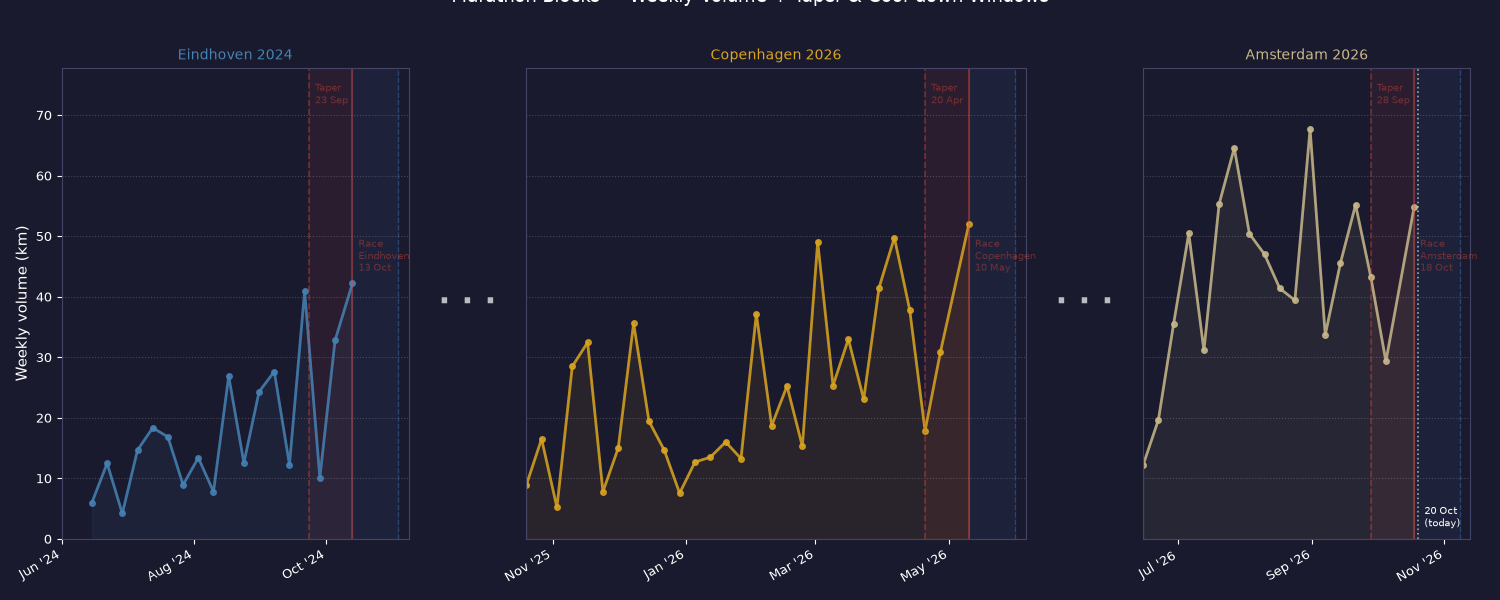

Amsterdam Marathon:  18 Oct 2026
Taper starts:        28 Sep 2026  (20 days before race)
Cool-down ends:      08 Nov 2026  (3 weeks after race)
Taper already started 22 days ago
Today:               20 Oct 2026


C:\Users\persif\AppData\Local\Temp\ipykernel_27160\3336856497.py:139: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`).Please use a specific unit instead.
  amsterdam_taper    = amsterdam_race - pd.Timedelta(days=TAPER_DAYS)
C:\Users\persif\AppData\Local\Temp\ipykernel_27160\3336856497.py:140: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`).Please use a specific unit instead.
  amsterdam_cooldown = amsterdam_race + pd.Timedelta(weeks=COOLDOWN_WEEKS)


In [6]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pandas as pd
import numpy as np
import os

TAPER_DAYS     = 20
COOLDOWN_WEEKS = 3

RACE_DATES = {
    "Eindhoven 2024":  pd.Timestamp("2024-10-13"),
    "Copenhagen 2026": pd.Timestamp("2026-05-10"),
    "Amsterdam 2026":  pd.Timestamp("2026-10-18"),
}

block_starts = {
    "Eindhoven 2024":  pd.Timestamp("2024-06-01"),
    "Copenhagen 2026": pd.Timestamp("2025-10-20"),
    "Amsterdam 2026":  pd.Timestamp("2026-06-15"),
}

COLORS = {
    "Eindhoven 2024":  "steelblue",
    "Copenhagen 2026": "goldenrod",
    "Amsterdam 2026":  "#C8B98A",
}

BG = "#1A1A2E"
today = pd.Timestamp.today().normalize()

DEDUP_DATES = {RACE_DATES["Eindhoven 2024"].normalize()}

def dedup_on_dates(df, dedup_dates):
    day_col    = df["start_date"].dt.normalize()
    mask_dedup = day_col.isin(dedup_dates)
    keep_idx   = df[mask_dedup].groupby(day_col[mask_dedup])["distance"].idxmax()
    return pd.concat([df[~mask_dedup], df.loc[keep_idx]]).sort_values("start_date")

# Pre-collect weekly data for all blocks
blocks_plot = {}
all_weekly_km = []
for name, start in block_starts.items():
    race         = RACE_DATES[name]
    cooldown_end = race + pd.Timedelta(weeks=COOLDOWN_WEEKS)
    plot_end     = min(race + pd.Timedelta(days=1), cooldown_end, today + pd.Timedelta(days=1))
    b = dedup_on_dates(
        runs_ml[(runs_ml["start_date"] >= start) & (runs_ml["start_date"] < plot_end)].copy(),
        DEDUP_DATES
    )
    b["week"]   = (b["start_date"] - start).dt.days // 7
    wk          = b.groupby("week")["distance"].sum()
    week_dates  = [start + pd.Timedelta(weeks=int(w)) for w in wk.index]
    # Snap last weekly marker to race date so the last dot aligns with the race line
    if week_dates and week_dates[-1] <= race:
        week_dates[-1] = race
    blocks_plot[name] = (week_dates, wk.values)
    all_weekly_km.extend(wk.values)

y_top = max(all_weekly_km) * 1.15 if all_weekly_km else 100

# Subplot widths proportional to each block's calendar span
widths = [(RACE_DATES[n] + pd.Timedelta(weeks=COOLDOWN_WEEKS) - s).days
          for n, s in block_starts.items()]

fig, axes = plt.subplots(
    1, 3, figsize=(15, 6), facecolor=BG,
    gridspec_kw={"width_ratios": widths},
    sharey=True,
)
fig.patch.set_facecolor(BG)

for ax, (name, start) in zip(axes, block_starts.items()):
    race         = RACE_DATES[name]
    taper_start  = race - pd.Timedelta(days=TAPER_DAYS)
    cooldown_end = race + pd.Timedelta(weeks=COOLDOWN_WEEKS)
    is_upcoming  = race >= today
    t_alpha  = 0.18 if is_upcoming else 0.08
    cd_alpha = 0.14 if is_upcoming else 0.06
    l_alpha  = 0.8  if is_upcoming else 0.4

    ax.set_facecolor(BG)
    ax.tick_params(colors="white", labelsize=9)
    for spine in ax.spines.values():
        spine.set_edgecolor("#444466")
    ax.grid(axis="y", alpha=0.2, linestyle=":")

    week_dates, wk_vals = blocks_plot[name]
    ax.plot(week_dates, wk_vals, color=COLORS[name], linewidth=2,
            marker="o", markersize=4, alpha=0.85)
    ax.fill_between(week_dates, 0, wk_vals, color=COLORS[name], alpha=0.08)

    ax.axvspan(taper_start, race, color="#E74C3C", alpha=t_alpha, zorder=0)
    ax.axvline(taper_start, color="#E74C3C", linewidth=1.2, linestyle="--", alpha=l_alpha)
    ax.text(taper_start, y_top * 0.97, f"  Taper\n  {taper_start.strftime('%d %b')}",
            color="#E74C3C", fontsize=7.5, va="top", alpha=l_alpha)

    ax.axvline(race, color="#E74C3C", linewidth=1.5, linestyle="-", alpha=l_alpha)
    ax.text(race, y_top * 0.60, f"  Race\n  {name.split()[0]}\n  {race.strftime('%d %b')}",
            color="#E74C3C", fontsize=7, va="center", alpha=l_alpha)

    ax.axvspan(race, cooldown_end, color="#4E9AF1", alpha=cd_alpha, zorder=0)
    ax.axvline(cooldown_end, color="#4E9AF1", linewidth=1, linestyle="--", alpha=l_alpha * 0.7)

    if name == "Amsterdam 2026" and today <= cooldown_end:
        ax.axvline(today, color="white", linewidth=1.2, linestyle=":", alpha=0.6)
        ax.text(today, y_top * 0.02, f"  {today.strftime('%d %b')}\n  (today)",
                color="white", fontsize=7, va="bottom")

    ax.set_xlim(start, cooldown_end + pd.Timedelta(days=5))
    ax.set_ylim(0, y_top)
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b '%y"))
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
    plt.setp(ax.get_xticklabels(), rotation=30, ha="right", color="white")
    ax.set_title(name, color=COLORS[name], fontsize=10, pad=6)

    if ax is not axes[0]:
        ax.tick_params(axis="y", left=False, labelleft=False)

axes[0].set_ylabel("Weekly volume (km)", color="white", fontsize=11)
fig.suptitle("Marathon Blocks — Weekly Volume + Taper & Cool-down Windows",
             color="white", fontsize=13, y=1.02)

# tight_layout first, then widen the inter-panel gaps so the "···" has room
plt.tight_layout()
fig.subplots_adjust(wspace=0.30)
fig.canvas.draw()

for i in range(2):
    x_mid = (axes[i].get_position().x1 + axes[i + 1].get_position().x0) / 2
    y_mid = (axes[0].get_position().y0  + axes[0].get_position().y1)  / 2
    fig.text(x_mid, y_mid, "· · ·", color="white", fontsize=22,
             ha="center", va="center", fontweight="bold", alpha=0.7)

plt.savefig(f"{os.path.join(os.getenv('FIGURES_DIR'), 'MarathonAnalytics')}/taper_detection.png", dpi=150,
            bbox_inches="tight", facecolor=BG)
plt.show()

amsterdam_race     = RACE_DATES["Amsterdam 2026"]
amsterdam_taper    = amsterdam_race - pd.Timedelta(days=TAPER_DAYS)
amsterdam_cooldown = amsterdam_race + pd.Timedelta(weeks=COOLDOWN_WEEKS)
days_to_taper      = (amsterdam_taper - today).days
print(f"Amsterdam Marathon:  {amsterdam_race.strftime('%d %b %Y')}")
print(f"Taper starts:        {amsterdam_taper.strftime('%d %b %Y')}  ({TAPER_DAYS} days before race)")
print(f"Cool-down ends:      {amsterdam_cooldown.strftime('%d %b %Y')}  ({COOLDOWN_WEEKS} weeks after race)")
if days_to_taper > 0:
    print(f"Days to taper:       {days_to_taper}")
else:
    print(f"Taper already started {abs(days_to_taper)} days ago")
print(f"Today:               {today.strftime('%d %b %Y')}")

## 4. Volume Forecast — Amsterdam 2026 (Holt's Exponential Smoothing)
Extrapolates the weekly volume trajectory from the last observed week using **Holt's double exponential smoothing with damping**. The model captures both the current level and the recent upward trend, while the damping parameter prevents the forecast from growing unrealistically far into the future. The taper weeks (3–1 before race day) are post-processed with fixed percentage reductions: 80 % → 60 % → 40 %.

C:\Users\persif\AppData\Local\Temp\ipykernel_27160\1325112538.py:11: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`).Please use a specific unit instead.
  cutoff    = race_ams + pd.Timedelta(days=1)  # hard cutoff — include race day, nothing after
C:\Users\persif\AppData\Local\Temp\ipykernel_27160\1325112538.py:93: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`).Please use a specific unit instead.
  ax.set_xlim(ams_start, race_ams + pd.Timedelta(days=5))


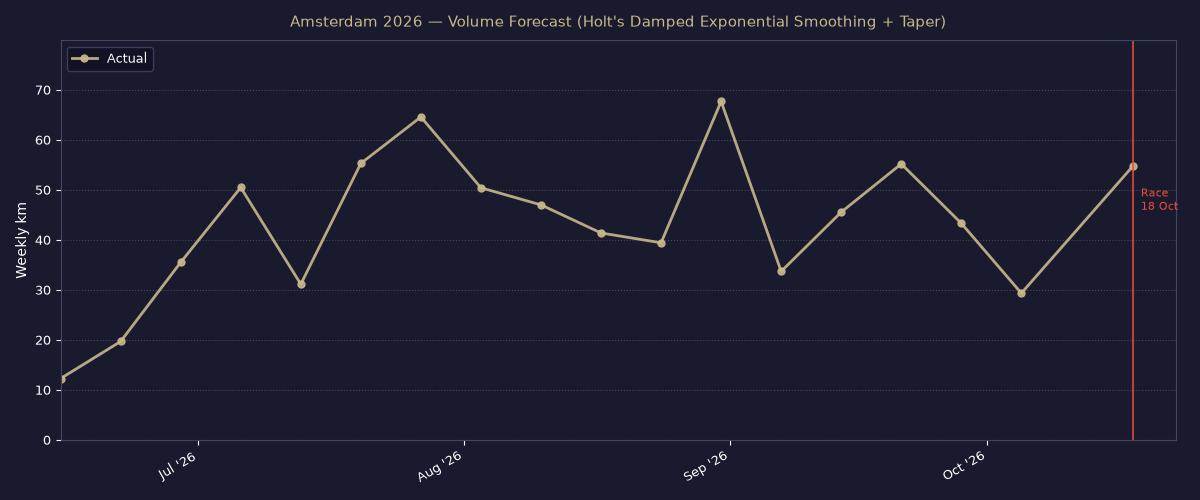

Race complete — showing actuals only.
Total training km  : 777 km
Peak week          : 67.7 km  (week 12)


In [5]:
from statsmodels.tsa.holtwinters import Holt
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import os

BG    = "#1A1A2E"
CREAM = "#C8B98A"

ams_start = pd.Timestamp("2026-06-15")
race_ams  = pd.Timestamp("2026-10-18")
cutoff    = race_ams + pd.Timedelta(days=1)  # hard cutoff — include race day, nothing after

mask = (runs_ml["start_date"] >= ams_start) & (runs_ml["start_date"] < cutoff)
b = runs_ml[mask].copy()
b["week_num"] = (b["start_date"] - ams_start).dt.days // 7
wk = b.groupby("week_num")["distance"].sum().reset_index(name="km")
wk["ds"] = ams_start + pd.to_timedelta(wk["week_num"] * 7, unit="D")

# Snap last weekly bucket to race date so the last dot aligns with the race line
if not wk.empty and wk["ds"].iloc[-1] <= race_ams:
    wk.loc[wk.index[-1], "ds"] = race_ams

last_ds  = wk["ds"].max()
last_val = wk["km"].iloc[-1]
h        = int((race_ams - last_ds).days / 7)

y_ceil = wk["km"].max() * 1.18

fig, ax = plt.subplots(figsize=(12, 5), facecolor=BG)
ax.set_facecolor(BG)
ax.tick_params(colors="white", labelsize=9)
for spine in ax.spines.values():
    spine.set_edgecolor("#444466")

ax.plot(wk["ds"], wk["km"],
        color=CREAM, linewidth=2, marker="o", markersize=5,
        label="Actual", alpha=0.9)

if h > 0:
    model  = Holt(wk["km"].values, damped_trend=True)
    fitted = model.fit(optimized=True)
    fc_raw = fitted.forecast(h)
    fc_ds  = [last_ds + pd.Timedelta(weeks=i + 1) for i in range(h)]

    sims      = fitted.simulate(h, repetitions=500, error='add', random_errors='bootstrap')
    ci_lo_raw = np.percentile(sims, 10, axis=1)
    ci_hi_raw = np.percentile(sims, 90, axis=1)

    TAPER_FACTORS = {3: 0.80, 2: 0.60, 1: 0.40}
    fc_adj    = np.array([max(0.0, v * TAPER_FACTORS.get(round((race_ams - d).days / 7), 1.0))
                          for d, v in zip(fc_ds, fc_raw)])
    ci_lo_adj = np.array([max(0.0, v * TAPER_FACTORS.get(round((race_ams - d).days / 7), 1.0))
                          for d, v in zip(fc_ds, ci_lo_raw)])
    ci_hi_adj = np.array([max(0.0, v * TAPER_FACTORS.get(round((race_ams - d).days / 7), 1.0))
                          for d, v in zip(fc_ds, ci_hi_raw)])

    taper_idx = next((i for i, d in enumerate(fc_ds)
                      if TAPER_FACTORS.get(round((race_ams - d).days / 7), 1.0) < 1.0), None)

    plot_ds  = [last_ds] + fc_ds
    plot_adj = np.concatenate([[last_val], fc_adj])
    fb_lo    = np.concatenate([[last_val], ci_lo_adj])
    fb_hi    = np.concatenate([[last_val], ci_hi_adj])
    y_ceil   = max(wk["km"].max(), fc_raw.max(), ci_hi_raw.max()) * 1.18

    ax.fill_between([last_ds] + fc_ds, fb_lo, fb_hi,
                    color="#E74C3C", alpha=0.15, zorder=0, label="80% CI")

    if taper_idx is not None:
        gap         = taper_idx + 1
        taper_start = fc_ds[taper_idx]
        xs1 = plot_ds[:gap + 1]
        ys1 = np.concatenate([plot_adj[:gap], [fc_raw[taper_idx]]])
        ax.plot(xs1, ys1, color="#E74C3C", linewidth=2, linestyle="--",
                marker="o", markersize=4, label="Forecast (taper-adjusted)", alpha=0.9)
        xs2 = [taper_start] + plot_ds[gap + 1:]
        ys2 = [fc_raw[taper_idx]] + list(plot_adj[gap + 1:])
        ax.plot(xs2, ys2, color="#E74C3C", linewidth=2, linestyle="--", marker="o", markersize=4, alpha=0.9)
        ax.plot([plot_ds[-1], race_ams], [plot_adj[-1], plot_adj[-1]],
                color="#E74C3C", linewidth=2, linestyle="--", alpha=0.9)
        ax.axvspan(taper_start, race_ams, color="#E74C3C", alpha=0.10, zorder=0, label="Taper window")
        ax.axvline(taper_start, color="#E74C3C", linewidth=1, linestyle="--", alpha=0.5)
        ax.text(taper_start, y_ceil * 0.97, f"  Taper\n  {taper_start.strftime('%d %b')}",
                color="#E74C3C", fontsize=7.5, va="top", alpha=0.8)
    else:
        ax.plot(plot_ds, plot_adj, color="#E74C3C", linewidth=2, linestyle="--",
                marker="o", markersize=4, label="Forecast (taper-adjusted)", alpha=0.9)

ax.axvline(race_ams, color="#E74C3C", linewidth=1.5, linestyle="-", alpha=0.8)
ax.text(race_ams, y_ceil * 0.60,
        f"  Race\n  {race_ams.strftime('%d %b')}", color="#E74C3C", fontsize=8, va="center")

ax.set_xlim(ams_start, race_ams + pd.Timedelta(days=5))
ax.set_ylim(0, y_ceil)
ax.set_ylabel("Weekly km", color="white", fontsize=10)
ax.grid(axis="y", alpha=0.2, linestyle=":")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b '%y"))
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=1))
plt.setp(ax.get_xticklabels(), rotation=30, ha="right", color="white")
ax.legend(facecolor="#111122", edgecolor="#444466", labelcolor="white", fontsize=9, loc="upper left")
ax.set_title("Amsterdam 2026 — Volume Forecast (Holt's Damped Exponential Smoothing + Taper)",
             color=CREAM, fontsize=11, pad=10)

plt.tight_layout()
plt.savefig(f"{os.path.join(os.getenv('FIGURES_DIR'), 'MarathonAnalytics')}/volume_forecast_holt_amsterdam_marathon.png", dpi=150,
            bbox_inches="tight", facecolor=BG)
plt.show()

if h > 0:
    p = fitted.params
    print(f"α  level smoothing : {p['smoothing_level']:.3f}")
    print(f"β  trend smoothing : {p['smoothing_trend']:.3f}")
    print(f"φ  damping factor  : {p['damping_trend']:.3f}")
    print(f"\nForecast horizon   : {h} weeks  (up to race day)")
    print(f"Peak raw forecast  : {fc_raw.max():.1f} km/week")
    print(f"Total forecast km  : {fc_adj.sum():.0f} km  (incl. taper)")
else:
    print("Race complete — showing actuals only.")
    print(f"Total training km  : {wk['km'].sum():.0f} km")
    print(f"Peak week          : {wk['km'].max():.1f} km  (week {int(wk.loc[wk['km'].idxmax(), 'week_num']) + 1})")